# 04 — The cluster area: existing lifts, radiation hours, and when the sun is on the snow

**Kok Zhailau ski terrain analytics — an independent open-data case study**
Dias Irishev · Geo & Weather Data Scientist, Almaty

Notebooks 01–03 work on a 69 km² rectangle around the Kok Zhailau plateau. This
one widens to the whole area the Almaty SuperSki cluster is reported to touch,
puts the **existing** lift network on the map, and answers three questions the
earlier notebooks did not:

1. Which terrain receives the most solar radiation — in **kWh/m²** and in
   **hours of direct sun**, which are not the same ranking.
2. **When** is the sun actually on the ski terrain — by month and by hour of day.
3. Does a **second satellite** agree with the Sentinel-2 snow record?

### On the area, and on honesty about it

The government statements describe the project's infrastructure in detail —
11 POMA cableways, 3S gondolas, base and upper stations, a mountain village by
BIG, a resort launch in December 2028 — but **publish no coordinates and no
project boundary**. The places they name are *Shymbulak* (modernisation),
the *Butakovka* and *Kimasar* gorges (stage 1), and *Pioneer* and *Oi-Qaragai*
(stage 2, to be linked by cable car). Kok Zhailau and Kumbel appear in the
cluster plan as reported on Wikipedia, not in the statements read here.

So the rectangle below is **derived, not given**: it is the smallest round
bounding box containing all of those named places. Lift lines drawn on these
maps are the **existing** network from OpenStreetMap. **No planned alignment is
shown, because none has been published.** Anyone who tells you otherwise from
open data is guessing.

In [1]:
import os
os.environ["KZ_AREA"] = "cluster"          # must be set before importing config

import json
import sys
from datetime import date
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import osm
from config import (AOI_BBOX_WGS84, AREA_LABEL, FOCUS_BAND, INTERIM, OUT_PNG,
                    OUT_TAB, OUT_TIF, OUTLOOK_YEAR, SEASONS, STUDY_AREAS)
from dem import write_geotiff
from grids import DEM_GRID, S2_GRID, wgs84_rect_area_km2
from pipeline_terrain import all_insolation, terrain
from viz import ELEV_CMAP, draw_osm, lift_legend, map_panel, save

pd.set_option("display.width", 170)
RUN_DATE = date.today().isoformat()
print(f"run date   : {RUN_DATE}")
print(f"area       : {AREA_LABEL}")
print(f"bbox       : {AOI_BBOX_WGS84}")
print(f"grid       : {DEM_GRID.shape[0]} x {DEM_GRID.shape[1]} @ 30 m = "
      f"{DEM_GRID.area_km2:.0f} km² (rectangle {wgs84_rect_area_km2():.0f} km² geodesic)")
print(f"note       : {STUDY_AREAS['cluster']['note']}")

run date   : 2026-11-24
area       : Almaty SuperSki cluster area
bbox       : (76.95, 43.07, 77.2, 43.24)
grid       : 647 x 694 @ 30 m = 404 km² (rectangle 384 km² geodesic)
note       : Chosen to contain every place the government statements name for the cluster (Shymbulak, Kimasar, Butakovka, Pioneer, Oi-Qaragai) plus Kok Zhailau and Kumbel. No official project boundary has been published; this rectangle is derived, not given.


In [2]:
t = terrain()
ins = all_insolation(t)
dem, slope, aspect, svf = t["dem"], t["slope"], t["aspect"], t["svf"]
print(f"elevation  : {np.nanmin(dem):.0f} – {np.nanmax(dem):.0f} m")
print(f"slope      : median {np.nanmedian(slope):.1f}°, p95 {np.nanpercentile(slope,95):.1f}°")
print(f"sky view   : median {np.nanmedian(svf):.3f}")

elevation  : 857 – 4279 m
slope      : median 28.2°, p95 42.3°
sky view   : median 0.885


## 1. What is actually on this mountain today

OpenStreetMap is the only open, georeferenced record of the existing network.
It is community-maintained, so completeness varies — but it is a fact base, and
every line below can be checked against the map.

In [3]:
features_all = osm.load()
feat = osm.clip(features_all)
lifts = sorted([f for f in feat["lift"] if f.length_m > 150], key=lambda f: -f.length_m)
lift_tbl = pd.DataFrame([{
    "name": f.name or "(unnamed)", "type": f.subkind,
    "length_m": round(f.length_m), "n_vertices": int(f.lon.size),
    "lon_min": round(float(f.lon.min()), 5), "lon_max": round(float(f.lon.max()), 5),
    "lat_min": round(float(f.lat.min()), 5), "lat_max": round(float(f.lat.max()), 5),
} for f in lifts])
lift_tbl.to_csv(OUT_TAB / "osm_existing_lifts.csv", index=False)
print(f"existing lift lines > 150 m inside the area: {len(lifts)}, "
      f"{lift_tbl.length_m.sum()/1000:.1f} km in total")
print(lift_tbl.head(14).to_string(index=False))
print(f"\nmapped downhill pistes: {len(feat['piste'])}, "
      f"{sum(f.length_m for f in feat['piste'])/1000:.1f} km")
print(f"lift stations: {len(feat['station'])} · named peaks: {len(feat['peak'])} · "
      f"named saddles: {len(feat['saddle'])}")
print(osm.to_geojson(feat, OUT_TIF.parent / "osm_reference_layers.geojson"))

existing lift lines > 150 m inside the area: 21, 21.1 km in total
                        name       type  length_m  n_vertices  lon_min  lon_max  lat_min  lat_max
Медеу - Шымбұлақ аспалы жолы    gondola      4520          21 77.05153 77.08070 43.12816 43.16280
                     Combi-1 mixed_lift      1820          14 77.08108 77.10004 43.11918 43.12786
                Aqtas Expres    gondola      1736           6 77.14874 77.16677 43.22738 43.23577
          Kok Tebe Cable Car    gondola      1629           7 76.95902 76.97567 43.23416 43.24235
                       KKD-4 chair_lift      1586          15 77.08073 77.09528 43.11796 43.12745
                   (unnamed)  cable_car      1501           3 77.16549 77.17690 43.21108 43.22171
                     Combi-2 mixed_lift      1122          10 77.09955 77.11089 43.11325 43.11898
   Pioneer ski area ski lift    platter       940           2 77.12780 77.13335 43.18689 43.19431
                 Left Talgar chair_lift       900   

### The places the statements name

In [4]:
ANCHORS = ["Shymbulak", "Medeu", "Kimasar", "Butakovskiy", "Talgar", "Pioneer",
           "Oi-Qaragai", "Qumbel", "Qumbeltau", "Kokterek", "Almaty", "Small Talgar"]
rows = []
for kind in ("peak", "saddle", "place", "area", "station"):
    for f in feat[kind]:
        if f.name and any(a.lower() in f.name.lower() for a in ANCHORS):
            rows.append({"name": f.name, "osm_kind": kind, "subkind": f.subkind,
                         "lon": round(float(f.lon.mean()), 5),
                         "lat": round(float(f.lat.mean()), 5),
                         "ele_m": f.tags.get("ele")})
anchor_tbl = pd.DataFrame(rows).drop_duplicates(subset=["name", "osm_kind"])
anchor_tbl.to_csv(OUT_TAB / "osm_named_anchors.csv", index=False)
print(anchor_tbl.to_string(index=False))

        name osm_kind       subkind      lon      lat  ele_m
     Pioneer     peak          peak 77.10478 43.08355   4031
   Shymbulak     peak          peak 77.11578 43.12434   3450
   Qumbeltau     peak          peak 77.04056 43.08490   3618
      Almaty     peak          peak 77.12012 43.08605 4330.9
      Qumbel     peak          peak 77.03130 43.11934   3221
       Medeu     peak          peak 77.09861 43.14929   2861
    Kokterek     peak          peak 77.01373 43.15189   2174
     Pioneer   saddle        saddle 77.10215 43.08306   3863
 Butakovskiy   saddle        saddle 77.13080 43.15642   2880
     Kimasar   saddle        saddle 77.08281 43.17116   2080
Small Talgar   saddle        saddle 77.13901 43.12136   2760
      Talgar   saddle        saddle 77.11122 43.11309   3200
  Oi-Qaragai    place    allotments 77.14871 43.22310   1800
       Medeu    place        suburb 77.05757 43.15944    NaN
  Oi-Qaragai     area winter_sports 77.14310 43.22878    NaN
   Shymbulak     area wi

## 2. The cluster area, with the existing network on it

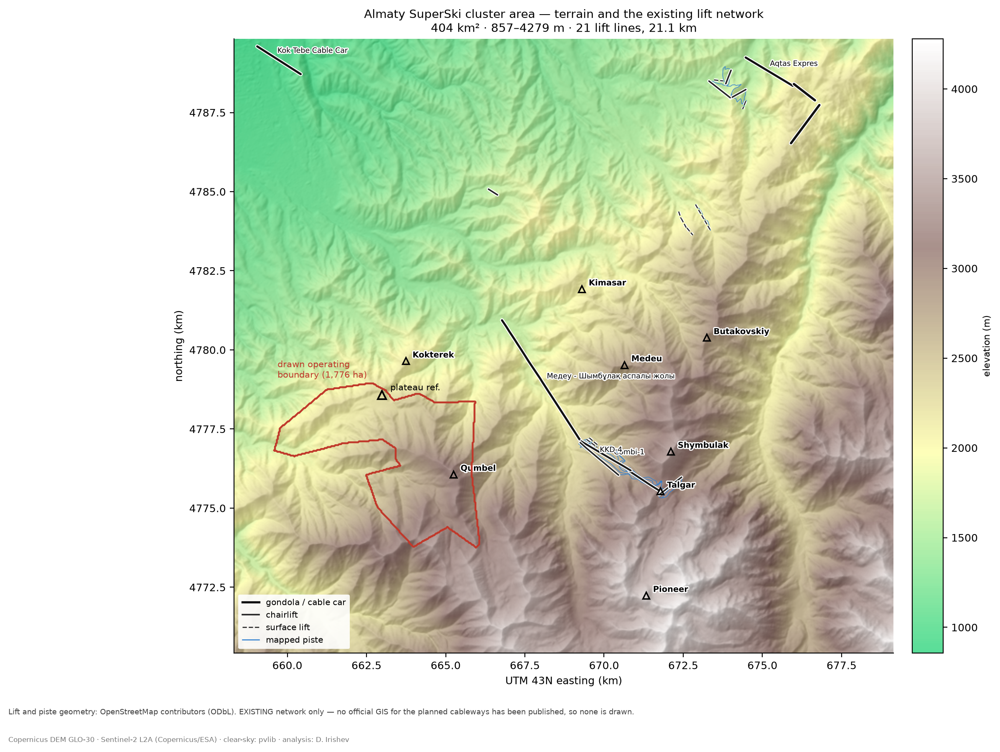

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/cluster/png/04_cluster_overview.png')

In [5]:
LABEL_PLACES = ["Shymbulak", "Medeu", "Kimasar", "Butakovskiy", "Talgar",
                "Pioneer", "Qumbel", "Kokterek"]
fig, ax = plt.subplots(figsize=(12.0, 8.4))
map_panel(ax, dem, DEM_GRID, ELEV_CMAP, title="", cbar_label="elevation (m)",
          dem=dem, shade=0.32, mark_plateau=True)
draw_osm(ax, feat, DEM_GRID, labels=LABEL_PLACES,
         label_kinds=("peak", "saddle", "place", "station"),
         lift_label_min_m=1500)
lift_legend(ax)
# the drawn operating boundary, for scale: the study area the rest of this
# release reports over, shown inside the cluster it sits in
import operating_area as _OA
_poly, _ = _OA.load()
_m = _OA.mask(DEM_GRID, _poly)
_ext = (DEM_GRID.xmin/1000, DEM_GRID.xmax/1000, DEM_GRID.ymin/1000, DEM_GRID.ymax/1000)
ax.contour(_m.astype(float), levels=[0.5], colors=["#c0392b"], linewidths=1.6,
           extent=_ext, origin="upper", zorder=8)
_rs, _cs = np.where(_m)
ax.annotate("drawn operating\nboundary (1,776 ha)",
            ((DEM_GRID.xmin + _cs.min()*DEM_GRID.res)/1000,
             (DEM_GRID.ymax - _rs.min()*DEM_GRID.res)/1000),
            fontsize=7.4, color="#c0392b", textcoords="offset points",
            xytext=(3, 5), zorder=9)
ax.set_title(f"{AREA_LABEL} — terrain and the existing lift network\n"
             f"{DEM_GRID.area_km2:.0f} km² · {np.nanmin(dem):.0f}–{np.nanmax(dem):.0f} m · "
             f"{len(lifts)} lift lines, {lift_tbl.length_m.sum()/1000:.1f} km")
fig.tight_layout()
save(fig, "04_cluster_overview.png",
     "Lift and piste geometry: OpenStreetMap contributors (ODbL). EXISTING network only — "
     "no official GIS for the planned cableways has been published, so none is drawn.")

## 3. Radiation: energy and hours are different questions

`kWh/m²` is how much energy a slope receives. **Sunshine hours** is how long the
sun is actually on it — above the astronomical horizon, above the ray-marched
terrain horizon, and in front of the slope plane. A broad south-west face and a
narrow south-east gully can collect similar energy while differing by hours of
daily sun, and only the second number tells a skier when to be there.

In [6]:
from pipeline_sun import SEASON_MONTHS, centroid
from pipeline_sun import run as run_sun

sun, sun_summary, sun_profile, masks, _ = run_sun(OUTLOOK_YEAR)
zone_names = [k for k, v in masks.items() if v.any()]
from zones import zone_table
ztbl = zone_table(masks, DEM_GRID, dem, slope)
ztbl.to_csv(OUT_TAB / "cluster_zones.csv", index=False)
print(ztbl.to_string(index=False))
print()
cols = ["month_name", "days", "median_sun_hours", "p95_sun_hours", "max_sun_hours",
        "median_hours_per_day", "max_hours_per_day"]
print(sun_summary[cols].to_string(index=False))

                   zone  pixels  area_km2  elev_min_m  elev_median_m  elev_max_m  slope_median_deg
            all terrain  449018   404.116       857.0         2153.0      4279.0              28.2
      skiable 15-35 deg  260546   234.491       874.0         2115.0      4279.0              27.1
existing lift corridors    8178     7.360       868.0         1988.0      3282.0              21.2
          mapped pistes    3334     3.001      1545.0         2483.0      3271.0              20.7
  Oi-Qaragai (OSM area)    1113     1.002      1549.0         1657.0      1837.0              21.3
   Shymbulak (OSM area)    2419     2.177      2069.0         2675.0      3253.0              21.0

month_name  days  median_sun_hours  p95_sun_hours  max_sun_hours  median_hours_per_day  max_hours_per_day
  November    30             161.5          253.0          289.8                  5.38               9.66
  December    31             129.5          237.0          277.0                  4.18        

November–April 2027 totals over the cluster area
  direct sunshine hours : median   1184 h, max   1905 h
  clear-sky insolation  : median    636 kWh/m², max   1584 kWh/m²
  correlation between the two rankings: r = 0.729


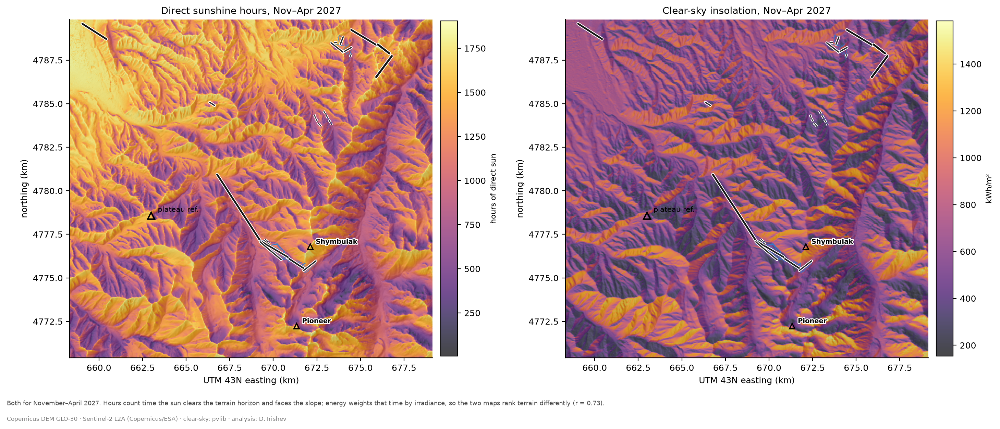

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/cluster/png/04_sun_hours_vs_energy.png')

In [7]:
season_hours = sum(sun[m]["hours"] for m in SEASON_MONTHS)
season_kwh = sum(ins[f"{OUTLOOK_YEAR}_{m:02d}"]["total"] for m in SEASON_MONTHS)
print(f"November–April {OUTLOOK_YEAR} totals over the cluster area")
print(f"  direct sunshine hours : median {np.nanmedian(season_hours):6.0f} h, "
      f"max {np.nanmax(season_hours):6.0f} h")
print(f"  clear-sky insolation  : median {np.nanmedian(season_kwh):6.0f} kWh/m², "
      f"max {np.nanmax(season_kwh):6.0f} kWh/m²")
r = np.corrcoef(season_hours[np.isfinite(season_kwh)].ravel(),
                season_kwh[np.isfinite(season_kwh)].ravel())[0, 1]
print(f"  correlation between the two rankings: r = {r:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14.6, 5.8))
map_panel(axes[0], season_hours, DEM_GRID, "inferno",
          title=f"Direct sunshine hours, Nov–Apr {OUTLOOK_YEAR}",
          cbar_label="hours of direct sun", dem=dem, shade=0.28)
draw_osm(axes[0], feat, DEM_GRID, labels=["Shymbulak", "Pioneer"], lift_label_min_m=1e9)
map_panel(axes[1], season_kwh, DEM_GRID, "inferno",
          title=f"Clear-sky insolation, Nov–Apr {OUTLOOK_YEAR}",
          cbar_label="kWh/m²", dem=dem, shade=0.28)
draw_osm(axes[1], feat, DEM_GRID, labels=["Shymbulak", "Pioneer"], lift_label_min_m=1e9)
fig.tight_layout()
save(fig, "04_sun_hours_vs_energy.png",
     f"Both for November–April {OUTLOOK_YEAR}. Hours count time the sun clears the "
     f"terrain horizon and faces the slope; energy weights that time by irradiance, "
     f"so the two maps rank terrain differently (r = {r:.2f}).")

### Where the radiation maximum actually is

Reported on **skiable** terrain (15–35°), because an unskiable sun-blasted cliff
is not a planning answer. Points are thinned to 400 m apart so the list is not
ten pixels of one ridge.

In [8]:
from sunhours import top_points

ski = masks["skiable 15-35 deg"]
extra = {"elevation_m": dem, "slope_deg": slope, "aspect_deg": aspect,
         "insolation_kwh_m2": season_kwh, "sun_hours": season_hours}
top_h = top_points(season_hours, DEM_GRID, n=10, mask=ski, extra=extra)
top_e = top_points(season_kwh, DEM_GRID, n=10, mask=ski, extra=extra)
top_h.to_csv(OUT_TAB / "max_sun_hours_points.csv", index=False)
top_e.to_csv(OUT_TAB / "max_insolation_points.csv", index=False)
print("Top 10 by DIRECT SUNSHINE HOURS, Nov–Apr, skiable terrain")
print(top_h[["rank", "lon", "lat", "value", "elevation_m", "slope_deg",
             "aspect_deg", "insolation_kwh_m2"]].to_string(index=False))
print("\nTop 10 by CLEAR-SKY ENERGY, same terrain")
print(top_e[["rank", "lon", "lat", "value", "elevation_m", "slope_deg",
             "aspect_deg", "sun_hours"]].to_string(index=False))
overlap = len(set(zip(top_h.easting, top_h.northing)) &
              set(zip(top_e.easting, top_e.northing)))
print(f"\npoints common to both top-10 lists: {overlap}")

Top 10 by DIRECT SUNSHINE HOURS, Nov–Apr, skiable terrain
 rank      lon      lat   value  elevation_m  slope_deg  aspect_deg  insolation_kwh_m2
    1 77.11803 43.12646 1893.50      3426.38      15.01      186.72            1150.26
    2 77.11175 43.07254 1890.75      4112.17      19.61      177.27            1277.69
    3 77.11567 43.07950 1890.50      4129.78      18.19      174.66            1252.50
    4 77.11755 43.09135 1885.75      4054.55      15.13      188.87            1200.47
    5 77.11713 43.13241 1885.50      3333.21      15.89      172.67            1158.24
    6 77.11533 43.12299 1884.00      3415.07      16.76      169.70            1177.79
    7 77.11994 43.08590 1878.00      4263.54      24.64      168.13            1355.69
    8 77.12644 43.10307 1865.50      3832.58      15.10      199.24            1166.44
    9 77.13221 43.07811 1849.75      3994.06      15.29      153.58            1161.24
   10 77.11227 43.12008 1844.00      3337.61      28.48      197.32     

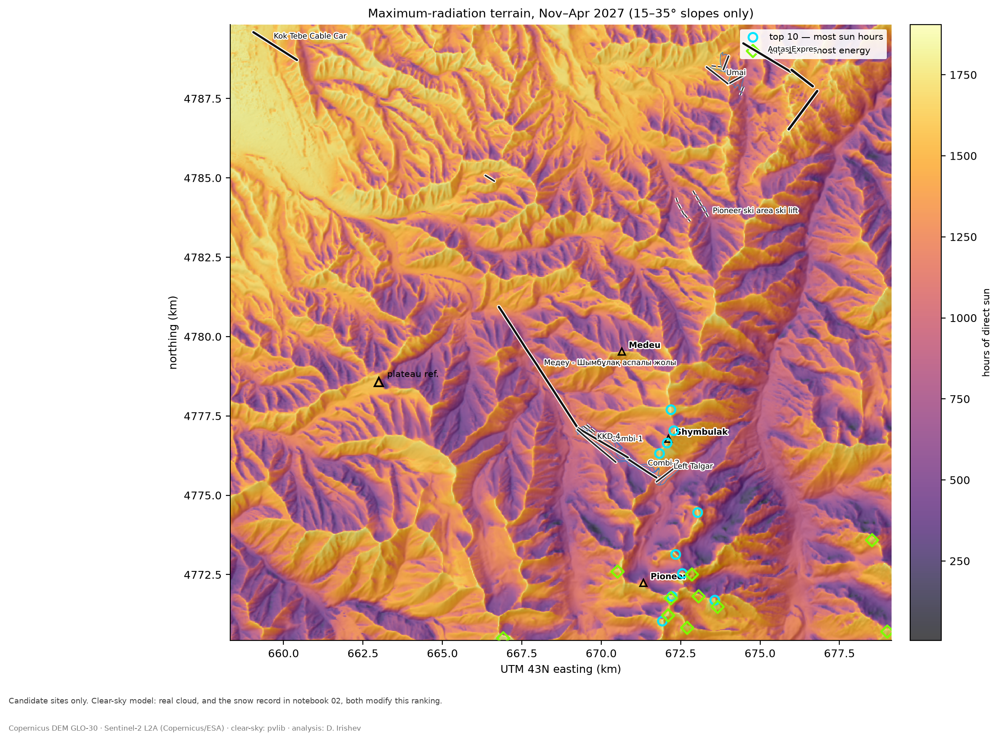

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/cluster/png/04_max_radiation_points.png')

In [9]:
fig, ax = plt.subplots(figsize=(11.6, 8.0))
map_panel(ax, season_hours, DEM_GRID, "inferno",
          title=f"Maximum-radiation terrain, Nov–Apr {OUTLOOK_YEAR} "
                f"(15–35° slopes only)",
          cbar_label="hours of direct sun", dem=dem, shade=0.3)
draw_osm(ax, feat, DEM_GRID, labels=["Shymbulak", "Pioneer", "Medeu", "Talgar"])
for df, mk, c, lab in ((top_h, "o", "#00e5ff", "most sun hours"),
                       (top_e, "D", "#7CFC00", "most energy")):
    xs, ys = df.easting / 1000, df.northing / 1000
    ax.scatter(xs, ys, s=52, marker=mk, facecolor="none", edgecolor=c,
               linewidth=1.7, zorder=9, label=f"top 10 — {lab}")
ax.legend(loc="upper right", fontsize=7.6, framealpha=0.9, edgecolor="none")
fig.tight_layout()
save(fig, "04_max_radiation_points.png",
     "Candidate sites only. Clear-sky model: real cloud, and the snow record in "
     "notebook 02, both modify this ranking.")

## 4. When is the sun on the ski terrain?

For every zone, the share of its pixels that are sunlit, by month and by hour of
the day (Asia/Almaty, UTC+5). This is the "best time to visit" question stated
precisely.

In [10]:
prof = sun_profile.copy()
pivot_zone = "existing lift corridors" if "existing lift corridors" in zone_names \
    else "skiable 15-35 deg"
pv = (prof[prof.zone == pivot_zone]
      .pivot(index="hour", columns="month", values="sunlit_fraction")
      .reindex(columns=SEASON_MONTHS))
pv.columns = [pd.Timestamp(2027, m, 1).strftime("%b") for m in pv.columns]
print(f"Sunlit fraction of '{pivot_zone}' by hour (rows) and month (columns)")
print((pv * 100).round(0).fillna(0).astype(int).to_string())

best = []
for zone in zone_names:
    z = prof[prof.zone == zone]
    for m in SEASON_MONTHS:
        zm = z[z.month == m]
        if zm.empty:
            continue
        peak = zm.loc[zm.sunlit_fraction.idxmax()]
        good = zm[zm.sunlit_fraction >= 0.5]
        best.append({
            "zone": zone, "month": m,
            "month_name": pd.Timestamp(2027, m, 1).strftime("%B"),
            "peak_hour": int(peak.hour),
            "peak_sunlit_fraction": round(float(peak.sunlit_fraction), 3),
            "hours_above_50pct_sunlit": int(len(good)),
            "window_start_hour": int(good.hour.min()) if len(good) else None,
            "window_end_hour": int(good.hour.max()) + 1 if len(good) else None,
        })
best_tbl = pd.DataFrame(best)
best_tbl.to_csv(OUT_TAB / "best_sun_window_by_zone_month.csv", index=False)
print("\n" + best_tbl[best_tbl.zone == pivot_zone].to_string(index=False))

Sunlit fraction of 'existing lift corridors' by hour (rows) and month (columns)
      Nov  Dec  Jan  Feb  Mar  Apr
hour                              
4       0    0    0    0    0    2
5       0    0    0    0    2   10
6       0    0    0    0    9   29
7       5    0    1    6   29   68
8      25   11   11   28   72   94
9      54   31   33   64   92   99
10     76   56   60   86   99  100
11     85   68   75   95  100  100
12     84   69   78   96  100  100
13     74   58   71   92  100  100
14     50   34   52   82   96   99
15     23   18   25   57   85   95
16     13    9   14   27   59   82
17      0    0    0   16   29   58
18      0    0    0    0   16   35

                   zone  month month_name  peak_hour  peak_sunlit_fraction  hours_above_50pct_sunlit  window_start_hour  window_end_hour
existing lift corridors     11   November         11                 0.849                         6                  9               15
existing lift corridors     12   December         

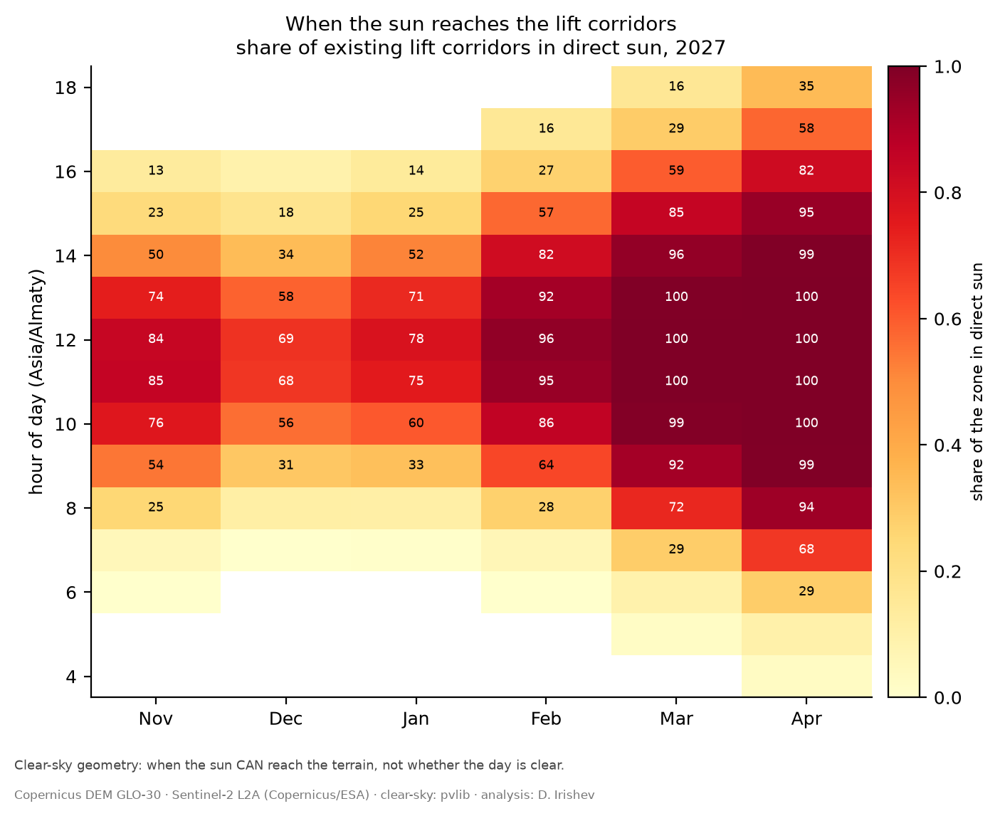

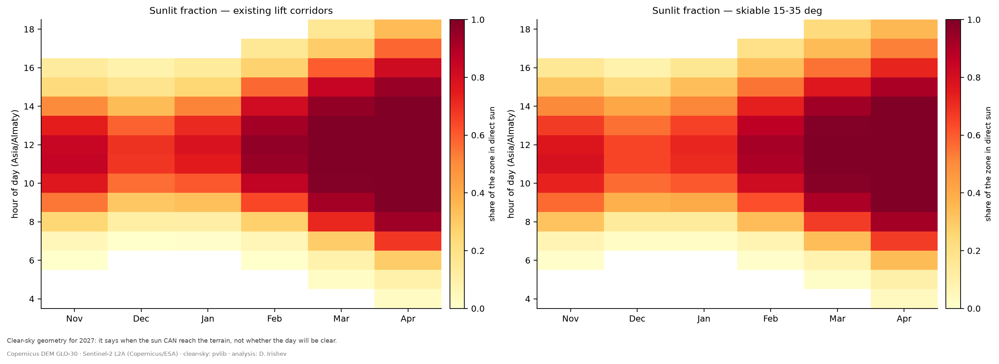

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/cluster/png/04_sunlit_fraction_month_hour.png')

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14.6, 4.9))
for ax, zone in zip(axes, [pivot_zone, "skiable 15-35 deg"]):
    z = prof[prof.zone == zone]
    grid_ = (z.pivot(index="hour", columns="month", values="sunlit_fraction")
             .reindex(columns=SEASON_MONTHS))
    im = ax.imshow(grid_.values, aspect="auto", origin="lower", cmap="YlOrRd",
                   vmin=0, vmax=1,
                   extent=(-0.5, len(SEASON_MONTHS) - 0.5,
                           grid_.index.min() - 0.5, grid_.index.max() + 0.5))
    ax.set_xticks(range(len(SEASON_MONTHS)))
    ax.set_xticklabels([pd.Timestamp(2027, m, 1).strftime("%b") for m in SEASON_MONTHS])
    ax.set_ylabel("hour of day (Asia/Almaty)")
    ax.set_title(f"Sunlit fraction — {zone}")
    plt.colorbar(im, ax=ax, fraction=0.042, pad=0.02).set_label(
        "share of the zone in direct sun", fontsize=8)
fig.tight_layout()
# compact single-panel version, shaped for the PDF brief
figc, axc = plt.subplots(figsize=(7.0, 5.3))
gz = (prof[prof.zone == pivot_zone]
      .pivot(index="hour", columns="month", values="sunlit_fraction")
      .reindex(columns=SEASON_MONTHS))
imc = axc.imshow(gz.values, aspect="auto", origin="lower", cmap="YlOrRd", vmin=0, vmax=1,
                 extent=(-0.5, len(SEASON_MONTHS)-0.5, gz.index.min()-0.5, gz.index.max()+0.5))
axc.set_xticks(range(len(SEASON_MONTHS)))
axc.set_xticklabels([pd.Timestamp(2027, m, 1).strftime("%b") for m in SEASON_MONTHS])
axc.set_ylabel("hour of day (Asia/Almaty)")
axc.set_title(f"When the sun reaches the lift corridors\n"
              f"share of {pivot_zone} in direct sun, {OUTLOOK_YEAR}")
for yy in range(int(gz.index.min()), int(gz.index.max()) + 1):
    for xi, mth in enumerate(SEASON_MONTHS):
        v = gz.loc[yy, mth] if (yy in gz.index and mth in gz.columns) else np.nan
        if np.isfinite(v) and v >= 0.12:
            axc.text(xi, yy, f"{v*100:.0f}", ha="center", va="center", fontsize=6.4,
                     color="black" if v < 0.65 else "white")
plt.colorbar(imc, ax=axc, fraction=0.045, pad=0.02).set_label(
    "share of the zone in direct sun", fontsize=8)
figc.tight_layout()
save(figc, "04_sunlit_heatmap_compact.png",
     "Clear-sky geometry: when the sun CAN reach the terrain, not whether the day is clear.")

save(fig, "04_sunlit_fraction_month_hour.png",
     f"Clear-sky geometry for {OUTLOOK_YEAR}: it says when the sun CAN reach the "
     f"terrain, not whether the day will be clear.")

## 5. Sun and snow together

Sun alone is not a reason to visit. The index below is simply
`sunlit fraction × snow detection frequency` for that month: the share of the
zone that is, at that hour, both in the sun and — on four seasons of satellite
record — usually snow-covered. It is a screening index, not a forecast.

In [12]:
from pipeline_snow import historical_days, load_days
from resample import mask_to_grid
from snow import snow_frequency
from sunhours import best_window

days, manifest, failed = load_days(verbose=True)
hist = historical_days(days)
print(f"\nSentinel-2 on the cluster grid: {len(manifest)} scenes, "
      f"{len(days)} unique dates, {len(failed)} failures")

# zone masks live on the 30 m terrain grid; the snow record is on the 20 m grid
masks_s2 = {k: mask_to_grid(v) for k, v in masks.items()}
print(f"zone masks resampled to the {S2_GRID.shape} Sentinel-2 grid")

monthly_freq, snow_by_month = {}, {}
for m in SEASON_MONTHS:
    sel = [d for d in hist if int(d["date"][5:7]) == m]
    if not sel:
        continue
    r = snow_frequency(sel, min_valid=4)
    monthly_freq[m] = r
    zmask = masks_s2[pivot_zone]
    v = r["frequency"][zmask]
    snow_by_month[m] = float(np.nanmedian(v[np.isfinite(v)]))
    print(f"  month {m:2d}: {r['n_dates']:3d} dates, coverage {r['coverage']*100:5.1f}%, "
          f"median snow frequency in '{pivot_zone}' = {snow_by_month[m]:.3f}")

combo = best_window(prof[prof.zone == pivot_zone], snow_by_month)
combo.to_csv(OUT_TAB / "sun_and_snow_index.csv", index=False)
top = combo.sort_values("sun_and_snow", ascending=False).head(12)
print(f"\nHighest sun-and-snow index for '{pivot_zone}':")
print(top[["month", "hour", "sunlit_fraction", "snow_frequency",
           "sun_and_snow"]].to_string(index=False))

  115 scenes: 115 cached, 0 to download



Sentinel-2 on the cluster grid: 115 scenes, 112 unique dates, 0 failures
zone masks resampled to the (970, 1040) Sentinel-2 grid
  month 11:  24 dates, coverage  77.7%, median snow frequency in 'existing lift corridors' = 0.592


  month 12:  16 dates, coverage  61.4%, median snow frequency in 'existing lift corridors' = 0.938
  month  1:  16 dates, coverage  67.3%, median snow frequency in 'existing lift corridors' = 1.000
  month  2:  13 dates, coverage  90.7%, median snow frequency in 'existing lift corridors' = 1.000
  month  3:  25 dates, coverage  96.1%, median snow frequency in 'existing lift corridors' = 0.938
  month  4:  17 dates, coverage  91.5%, median snow frequency in 'existing lift corridors' = 0.217

Highest sun-and-snow index for 'existing lift corridors':
 month  hour  sunlit_fraction  snow_frequency  sun_and_snow
     2    12           0.9621          1.0000        0.9621
     2    11           0.9478          1.0000        0.9478
     3    12           0.9995          0.9375        0.9370
     3    11           0.9992          0.9375        0.9368
     3    13           0.9950          0.9375        0.9328
     3    10           0.9884          0.9375        0.9266
     2    13           0.9

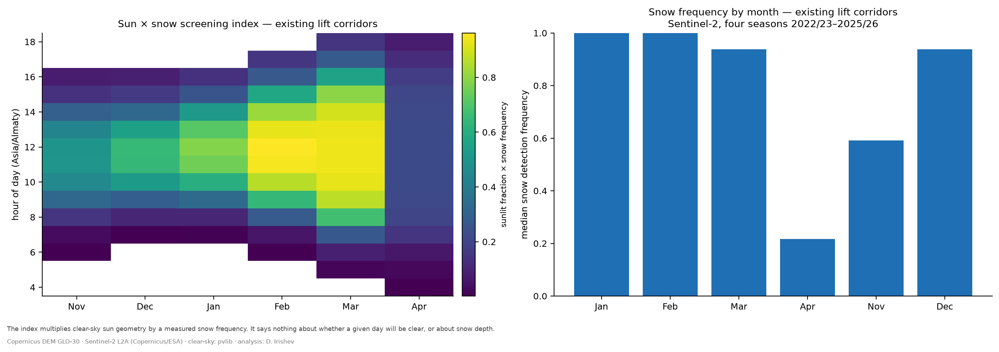

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/cluster/png/04_sun_and_snow_index.png')

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14.2, 4.6))
g = (combo.pivot(index="hour", columns="month", values="sun_and_snow")
     .reindex(columns=SEASON_MONTHS))
im = axes[0].imshow(g.values, aspect="auto", origin="lower", cmap="viridis",
                    extent=(-0.5, len(SEASON_MONTHS)-0.5,
                            g.index.min()-0.5, g.index.max()+0.5))
axes[0].set_xticks(range(len(SEASON_MONTHS)))
axes[0].set_xticklabels([pd.Timestamp(2027, m, 1).strftime("%b") for m in SEASON_MONTHS])
axes[0].set_ylabel("hour of day (Asia/Almaty)")
axes[0].set_title(f"Sun × snow screening index — {pivot_zone}")
plt.colorbar(im, ax=axes[0], fraction=0.042, pad=0.02).set_label(
    "sunlit fraction × snow frequency", fontsize=8)

mm = sorted(snow_by_month)
axes[1].bar([pd.Timestamp(2027, m, 1).strftime("%b") for m in mm],
            [snow_by_month[m] for m in mm], color="#1f6fb4")
axes[1].set_ylabel("median snow detection frequency")
axes[1].set_ylim(0, 1)
axes[1].set_title(f"Snow frequency by month — {pivot_zone}\n"
                  f"Sentinel-2, four seasons 2022/23–2025/26")
fig.tight_layout()
save(fig, "04_sun_and_snow_index.png",
     "The index multiplies clear-sky sun geometry by a measured snow frequency. It "
     "says nothing about whether a given day will be clear, or about snow depth.")

## 6. Does a second satellite agree?

One sensor is a single point of failure. Landsat 8/9 has a different orbit, a
different spectral response and a different atmospheric correction, and the USGS
ships its own independent snow flag in `QA_PIXEL`. If the two disagree badly,
the Sentinel-2 numbers in notebook 02 should not be trusted.

In [14]:
from alt_sources import fetch_landsat_all, registry_table

ls_recs = json.load(open(INTERIM / "landsat_records.json"))
ls = fetch_landsat_all(ls_recs, grid=S2_GRID, verbose=True)
ls_manifest = pd.DataFrame([s["meta"] for s in ls["scenes"]])
ls_manifest.to_csv(OUT_TAB / "landsat_manifest.csv", index=False)
print(f"\nLandsat 8/9 scenes used: {len(ls_manifest)}  (failures: {len(ls['failed'])})")
print(ls_manifest.groupby("platform").size().to_string())

r_int = np.corrcoef(ls_manifest.snow_fraction_of_valid,
                    ls_manifest.qa_snow_fraction_of_valid)[0, 1]
print(f"\nWithin Landsat: our NDSI rule vs the USGS QA snow flag, r = {r_int:.3f} "
      f"(n = {len(ls_manifest)})")

# Sentinel-2 and Landsat on the same dates (+/- 1 day)
s2m = manifest.copy()
pairs = []
for _, lrow in ls_manifest.iterrows():
    ld = pd.Timestamp(lrow["date"])
    near = s2m[(pd.to_datetime(s2m["date"]) - ld).abs() <= pd.Timedelta(days=1)]
    for _, srow in near.iterrows():
        pairs.append({"landsat_date": lrow["date"], "s2_date": srow["date"],
                      "landsat_snow": lrow["snow_fraction_of_valid"],
                      "s2_snow": srow["snow_fraction_of_valid"],
                      "landsat_valid": lrow["valid_fraction"],
                      "s2_valid": srow["valid_fraction"]})
pair_df = pd.DataFrame(pairs)
pair_df.to_csv(OUT_TAB / "landsat_sentinel2_pairs.csv", index=False)
rr = np.corrcoef(pair_df.landsat_snow, pair_df.s2_snow)[0, 1]
bias = (pair_df.s2_snow - pair_df.landsat_snow).mean()
print(f"Scene-aggregate: {len(pair_df)} pairs within 1 day, r = {rr:.3f}, "
      f"mean (S2 - Landsat) = {bias:+.3f}")

  77 Landsat scenes: 77 cached, 0 to download



Landsat 8/9 scenes used: 77  (failures: 0)
platform
landsat-8    35
landsat-9    42

Within Landsat: our NDSI rule vs the USGS QA snow flag, r = 0.879 (n = 77)


Scene-aggregate: 61 pairs within 1 day, r = 0.820, mean (S2 - Landsat) = +0.353


A scene-aggregate comparison is unfair: each sensor averages over *its own*
valid pixels, and the two valid masks differ — Landsat's `dilated_cloud` bit is
deliberately aggressive and removes a wide halo around every cloud. The honest
test compares the two **on the pixels both call usable, on the same date**.

In [15]:
s2_by_date = {}
for sc in __import__("s2").fetch_all(
        [r for v in json.load(open(INTERIM / "stac_records.json")).values() for r in v],
        verbose=False, grid=S2_GRID)["scenes"]:
    s2_by_date.setdefault(sc["meta"]["date"], []).append(sc)
ls_by_id = {sc["meta"]["scene_id"]: sc for sc in ls["scenes"]}

matched = []
for sc in ls["scenes"]:
    d = sc["meta"]["date"]
    if d not in s2_by_date:
        continue
    s2sc = s2_by_date[d][0]
    both = sc["valid"].astype(bool) & s2sc["valid"].astype(bool)
    if both.sum() < 20000:
        continue
    l_snow = sc["snow"].astype(bool)[both]
    s_snow = s2sc["snow"].astype(bool)[both]
    matched.append({
        "date": d, "landsat_scene": sc["meta"]["scene_id"],
        "s2_scene": s2sc["meta"]["scene_id"],
        "common_valid_pixels": int(both.sum()),
        "common_valid_fraction": round(float(both.mean()), 4),
        "landsat_snow": round(float(l_snow.mean()), 4),
        "s2_snow": round(float(s_snow.mean()), 4),
        "agreement": round(float((l_snow == s_snow).mean()), 4),
        "both_snow": round(float((l_snow & s_snow).mean()), 4),
        "only_s2": round(float((s_snow & ~l_snow).mean()), 4),
        "only_landsat": round(float((l_snow & ~s_snow).mean()), 4),
    })
match_df = pd.DataFrame(matched)
match_df.to_csv(OUT_TAB / "landsat_sentinel2_pixel_matched.csv", index=False)
if len(match_df):
    rm = np.corrcoef(match_df.landsat_snow, match_df.s2_snow)[0, 1]
    bm = (match_df.s2_snow - match_df.landsat_snow).mean()
    print(f"Same-date, same-pixel: {len(match_df)} dates, "
          f"{match_df.common_valid_pixels.sum()/1e6:.1f} M common pixels")
    print(f"  correlation r = {rm:.3f}")
    print(f"  mean difference (S2 - Landsat) = {bm:+.3f}")
    print(f"  mean per-pixel agreement = {match_df.agreement.mean()*100:.1f}%")
    print(f"  disagreement split: S2-only snow {match_df.only_s2.mean()*100:.1f}%, "
          f"Landsat-only snow {match_df.only_landsat.mean()*100:.1f}%")
    print(match_df[["date", "common_valid_fraction", "landsat_snow", "s2_snow",
                    "agreement"]].head(12).to_string(index=False))
else:
    rm, bm = float("nan"), float("nan")
    print("no same-date pairs with enough common valid pixels")

print(f"""
Reading of the result. Restricting both sensors to the pixels each calls usable
on the same date moves the correlation from {rr:.2f} to {rm:.2f} and cuts the
difference from {bias:+.2f} to {bm:+.2f}. Almost all of the apparent disagreement
was the two valid masks covering different ground, not the two sensors seeing
different snow.

What remains is one-sided: Sentinel-2 calls snow on {match_df.only_s2.mean()*100:.0f}% of common
pixels where Landsat does not, against {match_df.only_landsat.mean()*100:.0f}% the other way. That is the
direction a 30 m sensor resampled to a 20 m grid should err in — a part-snow
pixel averages below the NDSI threshold at the coarser footprint — and Landsat
also crosses about half an hour earlier. The two records are consistent; the
Sentinel-2 numbers in notebook 02 are not an artefact of one sensor.""")

Same-date, same-pixel: 25 dates, 8.5 M common pixels
  correlation r = 0.969
  mean difference (S2 - Landsat) = +0.096
  mean per-pixel agreement = 86.8%
  disagreement split: S2-only snow 11.4%, Landsat-only snow 1.8%
      date  common_valid_fraction  landsat_snow  s2_snow  agreement
2022-11-18                 0.3161        0.6823   0.8509     0.8015
2022-12-13                 0.2311        0.3689   0.5269     0.7496
2022-12-21                 0.5256        0.4682   0.5744     0.8343
2022-12-28                 0.2494        0.4256   0.6134     0.7884
2023-01-05                 0.3650        0.6940   0.7995     0.8367
2023-03-11                 0.7929        0.3750   0.4455     0.8924
2023-03-26                 0.2067        0.0865   0.0890     0.9922
2023-04-20                 0.1262        0.4558   0.4521     0.9900
2023-04-27                 0.1940        0.0717   0.0722     0.9995
2023-11-06                 0.5269        0.0128   0.0234     0.9889
2023-11-21                 0.3649

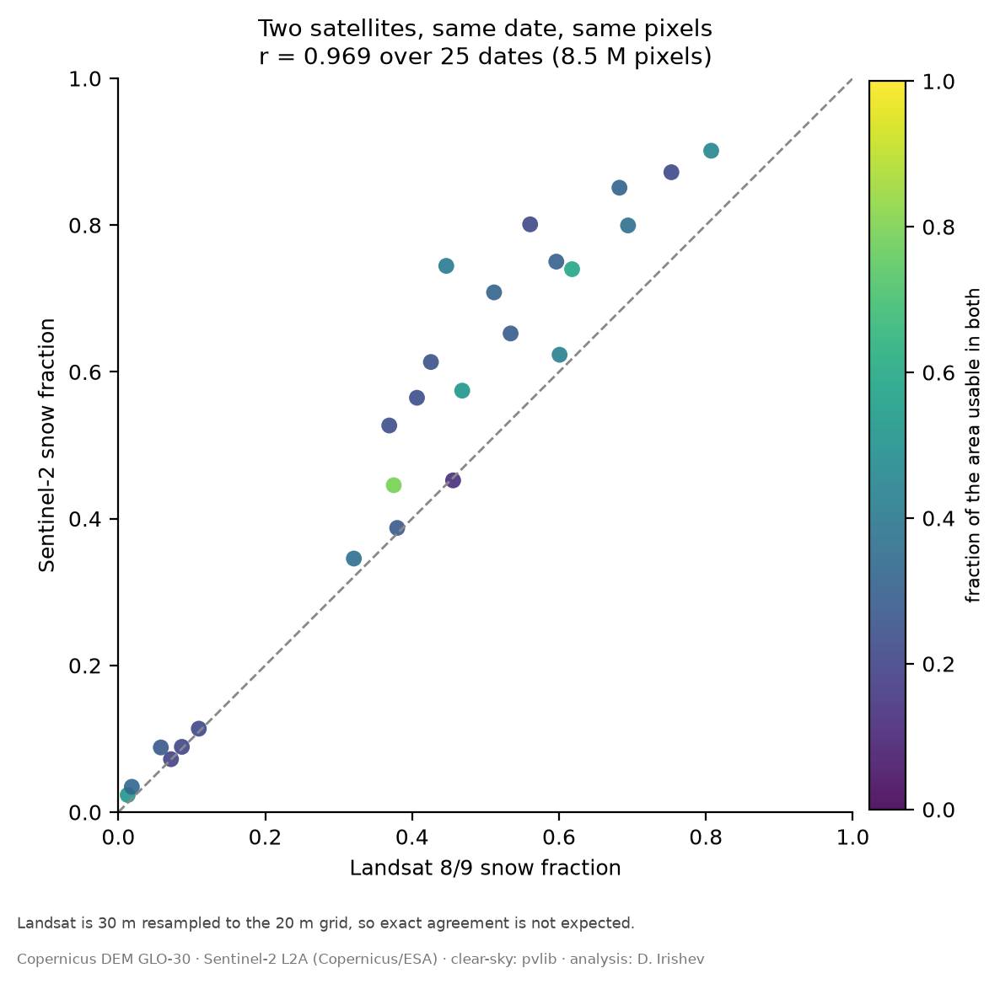

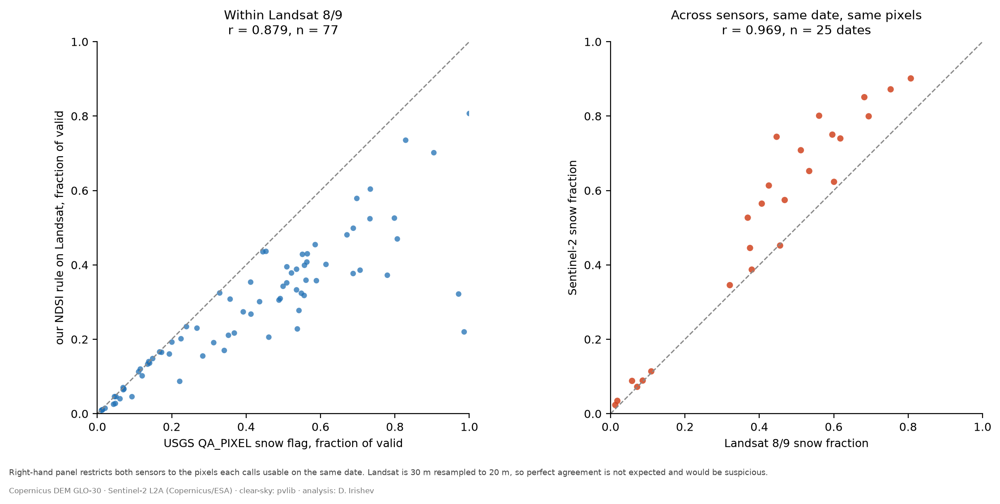

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/cluster/png/04_landsat_cross_validation.png')

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11.6, 5.2))
axes[0].scatter(ls_manifest.qa_snow_fraction_of_valid,
                ls_manifest.snow_fraction_of_valid, s=20, alpha=0.75,
                edgecolor="none", color="#1f6fb4")
axes[0].plot([0, 1], [0, 1], "--", color="#888", lw=1)
axes[0].set_xlabel("USGS QA_PIXEL snow flag, fraction of valid")
axes[0].set_ylabel("our NDSI rule on Landsat, fraction of valid")
axes[0].set_title(f"Within Landsat 8/9\nr = {r_int:.3f}, n = {len(ls_manifest)}")
axes[0].set_xlim(0, 1); axes[0].set_ylim(0, 1); axes[0].set_aspect("equal")
if len(match_df):
    axes[1].scatter(match_df.landsat_snow, match_df.s2_snow,
                    s=26, alpha=0.85, edgecolor="none", color="#d1441f")
    axes[1].plot([0, 1], [0, 1], "--", color="#888", lw=1)
    axes[1].set_xlabel("Landsat 8/9 snow fraction")
    axes[1].set_ylabel("Sentinel-2 snow fraction")
    axes[1].set_title(f"Across sensors, same date, same pixels\n"
                      f"r = {rm:.3f}, n = {len(match_df)} dates")
    axes[1].set_xlim(0, 1); axes[1].set_ylim(0, 1); axes[1].set_aspect("equal")
fig.tight_layout()
figv, axv = plt.subplots(figsize=(5.9, 5.4))
if len(match_df):
    sc_ = axv.scatter(match_df.landsat_snow, match_df.s2_snow,
                      c=match_df.common_valid_fraction, cmap="viridis",
                      s=46, alpha=0.9, edgecolor="none", vmin=0, vmax=1)
    axv.plot([0, 1], [0, 1], "--", color="#888", lw=1)
    plt.colorbar(sc_, ax=axv, fraction=0.045, pad=0.02).set_label(
        "fraction of the area usable in both", fontsize=8)
    axv.set_xlabel("Landsat 8/9 snow fraction")
    axv.set_ylabel("Sentinel-2 snow fraction")
    axv.set_title(f"Two satellites, same date, same pixels\n"
                  f"r = {rm:.3f} over {len(match_df)} dates "
                  f"({match_df.common_valid_pixels.sum()/1e6:.1f} M pixels)")
    axv.set_xlim(0, 1); axv.set_ylim(0, 1); axv.set_aspect("equal")
figv.tight_layout()
save(figv, "04_cross_validation_compact.png",
     "Landsat is 30 m resampled to the 20 m grid, so exact agreement is not expected.")

save(fig, "04_landsat_cross_validation.png",
     "Right-hand panel restricts both sensors to the pixels each calls usable on the "
     "same date. Landsat is 30 m resampled to 20 m, so perfect agreement is not "
     "expected and would be suspicious.")

### Elevation: three independent DEMs

In [17]:
dem_cmp = pd.read_csv(OUT_TAB / "dem_cross_validation.csv")
print("Copernicus DEM GLO-30 against two independent models, on the cluster grid:")
print(dem_cmp.to_string(index=False))
print("\nNASADEM is radar (SRTM, 2000) on the EGM96 geoid; ALOS AW3D30 is optical "
      "stereo (2006–2011), also EGM96; Copernicus GLO-30 is radar (TanDEM-X, "
      "2010–2015) on EGM2008. Their errors are largely independent, so agreement "
      "to a few metres is meaningful.")

Copernicus DEM GLO-30 against two independent models, on the cluster grid:
        dem  n_valid_pixels  elev_mean_difference_m  elev_median_difference_m  elev_std_difference_m  elev_p95_abs_difference_m  slope_mean_difference_deg  slope_std_difference_deg  correlation
    NASADEM          449018                    0.26                     -0.09                   7.40                      13.97                     -1.379                     3.738     0.999952
ALOS AW3D30          449018                    1.92                      1.59                   7.15                      12.68                      0.432                     3.106     0.999956

NASADEM is radar (SRTM, 2000) on the EGM96 geoid; ALOS AW3D30 is optical stereo (2006–2011), also EGM96; Copernicus GLO-30 is radar (TanDEM-X, 2010–2015) on EGM2008. Their errors are largely independent, so agreement to a few metres is meaningful.


### MODIS daily snow cover — filling the gaps between clear Sentinel-2 dates

In [18]:
from alt_sources import modis_snow_fraction, modis_snow_scenes

modis_recs = modis_snow_scenes("2023-02-01", "2023-04-30")
print(f"MODIS MOD10A1/MYD10A1 granules, Feb–Apr 2023: {len(modis_recs)}")
modis = modis_snow_fraction(modis_recs, grid=DEM_GRID)
modis = modis.dropna(subset=["mean_ndsi_snow_cover"])
modis = modis[modis.valid_fraction >= 0.5]          # drop heavily clouded days
modis_daily = (modis.groupby("date")
               .agg(snow_fraction_gt40=("snow_fraction_gt40", "mean"),
                    valid_fraction=("valid_fraction", "mean"),
                    granules=("scene_id", "size"))
               .reset_index().sort_values("date"))
modis_daily.to_csv(OUT_TAB / "modis_daily_snow.csv", index=False)
print(f"days with at least half the area unclouded: {len(modis_daily)} "
      f"of {modis.date.nunique()} days read")
print(modis_daily.head(10).to_string(index=False))

s2_dates = sorted({d["date"] for d in hist
                   if "2023-02" <= d["date"] <= "2023-04-30"})
print(f"\nSentinel-2 usable dates in the same window: {len(s2_dates)}")
print(f"MODIS adds {len(modis_daily) - len(set(s2_dates) & set(modis_daily.date))} "
      f"days on which Sentinel-2 has no usable scene.")

MODIS MOD10A1/MYD10A1 granules, Feb–Apr 2023: 197


days with at least half the area unclouded: 46 of 46 days read
      date  snow_fraction_gt40  valid_fraction  granules
2023-02-01             0.82745         0.86815         2
2023-02-08             0.85560         0.62070         1
2023-02-10             0.96000         0.75920         1
2023-02-11             0.95695         0.80545         2
2023-02-12             0.89660         0.52480         1
2023-02-13             0.90360         0.91810         1
2023-02-15             0.88530         0.76550         1
2023-02-20             0.85220         0.84365         2
2023-02-23             0.93250         0.62600         1
2023-02-27             0.89740         0.70960         1

Sentinel-2 usable dates in the same window: 14
MODIS adds 36 days on which Sentinel-2 has no usable scene.


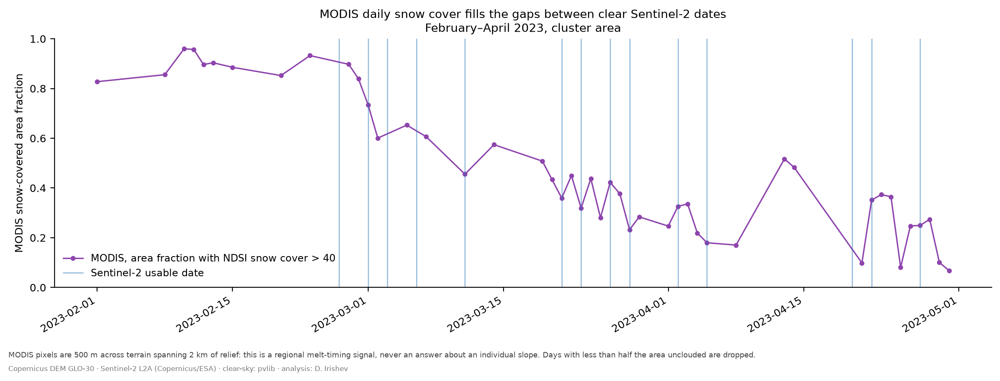

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/cluster/png/04_modis_daily_timeseries.png')

In [19]:
fig, ax = plt.subplots(figsize=(12.0, 4.2))
md = pd.to_datetime(modis_daily["date"])
ax.plot(md, modis_daily["snow_fraction_gt40"], "-o", ms=3.2, lw=1.2,
        color="#8e44ad", label="MODIS, area fraction with NDSI snow cover > 40")
for i, d in enumerate(s2_dates):
    ax.axvline(pd.Timestamp(d), color="#1f6fb4", lw=0.9, alpha=0.5,
               label="Sentinel-2 usable date" if i == 0 else None)
ax.set_ylabel("MODIS snow-covered area fraction")
ax.set_ylim(0, 1)
ax.set_title("MODIS daily snow cover fills the gaps between clear Sentinel-2 dates\n"
             "February–April 2023, cluster area")
ax.legend(frameon=False, fontsize=8.5, loc="lower left")
fig.autofmt_xdate()
fig.tight_layout()
save(fig, "04_modis_daily_timeseries.png",
     "MODIS pixels are 500 m across terrain spanning 2 km of relief: this is a "
     "regional melt-timing signal, never an answer about an individual slope. Days "
     "with less than half the area unclouded are dropped.")

## 7. The source registry

What this release uses, and what the next person should reach for.

In [20]:
reg = registry_table()
reg.to_csv(OUT_TAB / "data_source_registry.csv", index=False)
with pd.option_context("display.max_colwidth", 54):
    print(reg[["name", "role", "used", "resolution", "revisit", "access"]]
          .to_string(index=False))
print(f"\n{int(reg.used.sum())} of {len(reg)} sources are used in this release; "
      f"the rest are documented with their endpoint and cost of entry.")

                                   name                                  role  used resolution                                  revisit                                                         access
                         Sentinel-2 L2A           primary optical snow record  True    10-20 m                    5 days (2 satellites)                                               open, no account
            Landsat 8/9 Collection 2 L2       independent optical cross-check  True       30 m                  8 days (two satellites) open, anonymous SAS signing via the planetary-computer package
           MODIS MOD10A1 / MYD10A1 v061           daily regional snow context  True      500 m                     daily, two platforms                                                open, anonymous
                                NASADEM                 elevation cross-check  True       30 m    single epoch (SRTM 2000, reprocessed)                                                open, anonymous
     

## 8. Outputs

In [21]:
written = [
    write_geotiff(OUT_TIF / "cluster_elevation_m.tif", dem, DEM_GRID, nodata=-9999,
                  description="Copernicus DEM GLO-30, cluster area"),
    write_geotiff(OUT_TIF / "cluster_slope_deg.tif", slope, DEM_GRID, nodata=-9999,
                  description="slope, Horn 3x3"),
    write_geotiff(OUT_TIF / "cluster_aspect_deg.tif", aspect, DEM_GRID, nodata=-9999,
                  description="aspect, degrees CW from true north"),
    write_geotiff(OUT_TIF / "cluster_sky_view_factor.tif", svf, DEM_GRID, nodata=-9999,
                  description="sky view factor, Dozier & Frew 1990"),
    write_geotiff(OUT_TIF / f"sun_hours_nov_apr_{OUTLOOK_YEAR}.tif", season_hours,
                  DEM_GRID, nodata=-9999,
                  description=f"direct sunshine hours, Nov-Apr {OUTLOOK_YEAR}"),
    write_geotiff(OUT_TIF / f"insolation_nov_apr_{OUTLOOK_YEAR}_kwh_m2.tif", season_kwh,
                  DEM_GRID, nodata=-9999,
                  description=f"clear-sky POA insolation, Nov-Apr {OUTLOOK_YEAR}"),
]
for m in SEASON_MONTHS:
    written.append(write_geotiff(
        OUT_TIF / f"sun_hours_{OUTLOOK_YEAR}_{m:02d}.tif", sun[m]["hours"], DEM_GRID,
        nodata=-9999, description=f"direct sunshine hours, {OUTLOOK_YEAR}-{m:02d}"))
for name, mk in masks.items():
    slug = (name.replace(" ", "_").replace("-", "").replace("(", "")
            .replace(")", "").lower())
    written.append(write_geotiff(OUT_TIF / f"zone_{slug}.tif", mk.astype("uint8"),
                                 DEM_GRID, nodata=255, dtype="uint8",
                                 description=f"zone mask: {name}"))
for m, r in monthly_freq.items():
    written.append(write_geotiff(
        OUT_TIF / f"cluster_snow_frequency_month_{m:02d}.tif", r["frequency"],
        S2_GRID, nodata=-9999,
        description=f"snow detection frequency, month {m}, 4 seasons"))

json.dump({
    "run_date": RUN_DATE, "area": "cluster", "bbox": list(AOI_BBOX_WGS84),
    "area_km2": round(DEM_GRID.area_km2, 1),
    "derivation": STUDY_AREAS["cluster"]["note"],
    "osm": {"lifts_over_150m": len(lifts),
            "lift_km": round(float(lift_tbl.length_m.sum()) / 1000, 2),
            "pistes": len(feat["piste"]),
            "licence": "ODbL, OpenStreetMap contributors"},
    "sentinel2_scenes": int(len(manifest)), "landsat_scenes": int(len(ls_manifest)),
    "sun_hours_year": OUTLOOK_YEAR, "zones": zone_names,
    "cross_validation": {
        "landsat_internal_r": round(float(r_int), 4),
        "landsat_vs_sentinel2_r_scene_aggregate": round(float(rr), 4),
        "landsat_vs_sentinel2_r_pixel_matched": (round(float(rm), 4)
                                                 if len(match_df) else None),
        "landsat_vs_sentinel2_bias_pixel_matched": (round(float(bm), 4)
                                                    if len(match_df) else None),
        "dem": dem_cmp.to_dict(orient="records"),
    },
}, open(OUT_TIF / "cluster_metadata.json", "w"), indent=1)

print(f"{len(written)} GeoTIFFs written to {OUT_TIF}")
for p in written:
    print(f"  {p.name}")

24 GeoTIFFs written to /Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/cluster/geotiff
  cluster_elevation_m.tif
  cluster_slope_deg.tif
  cluster_aspect_deg.tif
  cluster_sky_view_factor.tif
  sun_hours_nov_apr_2027.tif
  insolation_nov_apr_2027_kwh_m2.tif
  sun_hours_2027_11.tif
  sun_hours_2027_12.tif
  sun_hours_2027_01.tif
  sun_hours_2027_02.tif
  sun_hours_2027_03.tif
  sun_hours_2027_04.tif
  zone_all_terrain.tif
  zone_skiable_1535_deg.tif
  zone_existing_lift_corridors.tif
  zone_mapped_pistes.tif
  zone_oiqaragai_osm_area.tif
  zone_shymbulak_osm_area.tif
  cluster_snow_frequency_month_11.tif
  cluster_snow_frequency_month_12.tif
  cluster_snow_frequency_month_01.tif
  cluster_snow_frequency_month_02.tif
  cluster_snow_frequency_month_03.tif
  cluster_snow_frequency_month_04.tif
